# How do we scale past a simple linear regression ?

Everything so far has had one measurement and two parameters:

$$\color{#56D4F5}{\hat{y}} = \color{#FFB454}{a} \cdot \color{#7EE787}{x} + \color{#FFB454}{b}$$

The auction house does not only weigh its sculptures. It records their height, their age, the
artist, the material. Every one of those is a number we could be using, and we are throwing
them away.

This notebook adds them, one at a time, until something breaks. What breaks is not the maths.
**It is the drawing.** And the way we write the formula is what we invent to live without it.

# Setup

In [ ]:
# ABOUTME: From one measurement to N: the line, the plane, the dot product and the ones column.
# ABOUTME: Ends on the matrix gradient, checked against the scalar derivatives from notebook 3.
%matplotlib widget

import pickle

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

with open("Teach_linear_regression.pkl", "rb") as f:
    (
        x, y, COEF_A, COEF_B,
        COEF_A_MIN, COEF_A_MAX,
        COEF_B_MIN, COEF_B_MAX,
        WORST_A_PARAM, WORST_B_PARAM,
        MIN_COST, MAX_COST,
        MIN_VALUE, MAX_VALUE, NB_ELEMENTS,
    ) = pickle.load(f)


def get_cost(y, y_hat):
    return ((y - y_hat) ** 2).sum()


def best_parameters(*measurements):
    """The best possible parameters for these measurements, so every loss below is the best
    reachable one and the comparisons are fair. How this works is notebook 5's problem."""
    design = np.column_stack([np.ones(NB_ELEMENTS), *measurements])
    theta, *_ = np.linalg.lstsq(design, y, rcond=None)
    return theta, get_cost(y, design @ theta)

In [ ]:
# The same sculptures, with the two other things the auction house wrote down. They are built
# here from what the weight alone could NOT explain, which is the only honest way to invent a
# measurement after the fact: a height that tells us nothing new would make this notebook lie.
rng = np.random.default_rng(7)

leftover = y - (COEF_A * x + COEF_B)                    # what weight misses
height = np.round(1.25 + 0.26 * leftover / leftover.std() + rng.normal(0, 0.18, NB_ELEMENTS), 2)

still_missing = leftover - np.polyval(np.polyfit(height, leftover, 1), height)
age = np.round(110 + 26 * still_missing / still_missing.std() + rng.normal(0, 20, NB_ELEMENTS))

print(f"weight {x.min():.2f} to {x.max():.2f} kg")
print(f"height {height.min():.2f} to {height.max():.2f} m")
print(f"age    {age.min():.0f} to {age.max():.0f} years")
print(f"\nsculpture #0: weight {x[0]:.2f} kg, height {height[0]:.2f} m, "
      f"age {age[0]:.0f} years, sold for {y[0]:.2f}")

weight 0.00 to 1.00 kg
height 0.36 to 1.89 m
age    37 to 190 years

sculpture #0: weight 0.00 kg, height 0.95 m, age 87 years, sold for 1.64


# 1. One measurement: a line

$$\color{#56D4F5}{\text{price}} =
\color{#FFB454}{\theta_1} \cdot \color{#7EE787}{\text{weight}} + \color{#FFB454}{\theta_0}$$

Same formula as always, with $\color{#FFB454}{a}$ renamed $\color{#FFB454}{\theta_1}$ and
$\color{#FFB454}{b}$ renamed $\color{#FFB454}{\theta_0}$. The renaming is the whole point:
$\color{#FFB454}{a}, \color{#FFB454}{b}, \color{#FFB454}{c}, \dots$ runs out of letters and tells
you nothing about which measurement each one belongs to. $\color{#FFB454}{\theta_1}$ is the one
that multiplies measurement 1.

$\color{#FFB454}{\theta_0}$ multiplies nothing. It is the price a sculpture starts at before we
have measured anything about it.

# 2. Two measurements: a plane

Add the height. One more measurement, so one more parameter:

$$\color{#56D4F5}{\text{price}} =
\color{#FFB454}{\theta_1} \cdot \color{#7EE787}{\text{weight}} +
\color{#FFB454}{\theta_2} \cdot \color{#7EE787}{\text{height}} + \color{#FFB454}{\theta_0}$$

Both panels run on the same $\color{#FFB454}{\theta_0}$ and $\color{#FFB454}{\theta_1}$, so those
two sliders move both of them at once. Only the right panel also has
$\color{#FFB454}{\theta_2}$: it is the very same model, with one more measurement allowed in.

The thick grey line is the best any line can ever do on weight alone. With the first two sliders
you can match it, never beat it. **Push $\color{#FFB454}{\theta_2}$ and beat it on the right.**

<details>
<summary>why "taller than average" and not just the height ?</summary>

$\color{#FFB454}{\theta_2}$ below multiplies how much taller than the average sculpture this one
is, rather than its height in metres. It is the same model and it reaches the same loss, with
$\color{#FFB454}{\theta_0}$ shifted to absorb the difference.

The reason is the slider. The average sculpture is 1.22 m tall, so with raw heights, turning
$\color{#FFB454}{\theta_2}$ up adds about $1.22 \times \color{#FFB454}{\theta_2}$ to **every**
prediction: the plane lifts off the data faster than it tilts, and you would have to drag
$\color{#FFB454}{\theta_0}$ down by hand just to stay level. Measuring the height from the average
separates the two, so one slider does one thing.
</details>

interactive(children=(FloatSlider(value=2.2, description='theta_0:', max=4.0, min=-1.0, step=0.05, style=Slide…

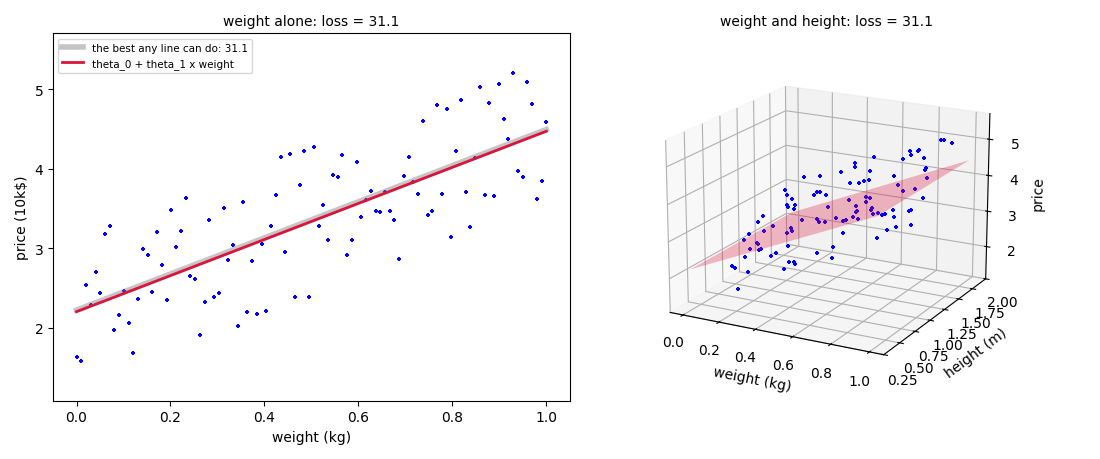

In [ ]:
# One figure, built once, redrawn by the callback.
fig_plane = plt.figure(figsize=(11, 4.6))
ax_line = fig_plane.add_subplot(1, 2, 1)
ax_plane = fig_plane.add_subplot(1, 2, 2, projection="3d")

BEST_1, LOSS_1 = best_parameters(x)
AVG_HEIGHT = height.mean()
# Both panels share one price axis, so a loss you read on the left is comparable to the right.
PRICE_LO, PRICE_HI = y.min() - 0.5, y.max() + 0.5
GRID_W, GRID_H = np.meshgrid(np.linspace(x.min(), x.max(), 12),
                             np.linspace(height.min(), height.max(), 12))
WIDE = {"description_width": "initial"}


@interact(
    theta_0=widgets.FloatSlider(value=2.20, min=-1, max=4, step=0.05,
                                description="theta_0:", style=WIDE),
    theta_1=widgets.FloatSlider(value=2.27, min=0, max=4, step=0.05,
                                description="theta_1 (weight):", style=WIDE),
    theta_2=widgets.FloatSlider(value=0.00, min=0, max=3, step=0.05,
                                description="theta_2 (taller than average):", style=WIDE),
)
def the_plane(theta_0, theta_1, theta_2):
    ax_line.clear()
    ax_plane.clear()

    # The same two parameters draw both panels. The right one gets the height on top.
    y_line = theta_0 + theta_1 * x
    y_plane = y_line + theta_2 * (height - AVG_HEIGHT)

    ax_line.plot(x, BEST_1[1] * x + BEST_1[0], c="gray", lw=4, alpha=0.45,
                 label=f"the best any line can do: {LOSS_1:.1f}")
    ax_line.scatter(x, y, c="b", s=8, marker="+")
    ax_line.plot(x, y_line, c="crimson", lw=2, label="theta_0 + theta_1 x weight")
    ax_line.set_xlabel("weight (kg)"); ax_line.set_ylabel("price (10k$)")
    ax_line.set_ylim(PRICE_LO, PRICE_HI)
    ax_line.legend(loc="upper left", fontsize=7.5)
    ax_line.set_title(f"weight alone: loss = {get_cost(y, y_line):.1f}", fontsize=10)

    ax_plane.scatter(x, height, y, c="b", s=8, marker="+", depthshade=False)
    ax_plane.plot_surface(GRID_W, GRID_H,
                          theta_0 + theta_1 * GRID_W + theta_2 * (GRID_H - AVG_HEIGHT),
                          color="crimson", alpha=0.3, linewidth=0, shade=False)
    ax_plane.set_xlabel("weight (kg)"); ax_plane.set_ylabel("height (m)")
    ax_plane.set_zlabel("price", labelpad=2)
    ax_plane.set_zlim(PRICE_LO, PRICE_HI)
    ax_plane.view_init(elev=18, azim=-62)
    ax_plane.set_title(f"weight and height: loss = {get_cost(y, y_plane):.1f}", fontsize=10)

    fig_plane.tight_layout()
    fig_plane.canvas.draw_idle()

A plane is not a new idea. It is the same line, allowed to tilt the other way as well:
$\color{#FFB454}{\theta_1}$ tilts it along weight, $\color{#FFB454}{\theta_2}$ tilts it along
height, and $\color{#FFB454}{\theta_0}$ slides the whole thing up and down.

Every measurement we add is one more direction the fit is allowed to tilt in, which is why the
loss can only get better.

# 3. Three measurements: now draw it

Add the age. The formula barely changes:

$$\text{price} = \theta_1 \cdot \text{weight} + \theta_2 \cdot \text{height}
+ \theta_3 \cdot \text{age} + \theta_0$$

The picture, on the other hand, is finished.

loss: 31.1 -> 9.5 -> 3.0   (every measurement helps)
3 measurements, theta = [-0.638  2.066  1.69   0.008]


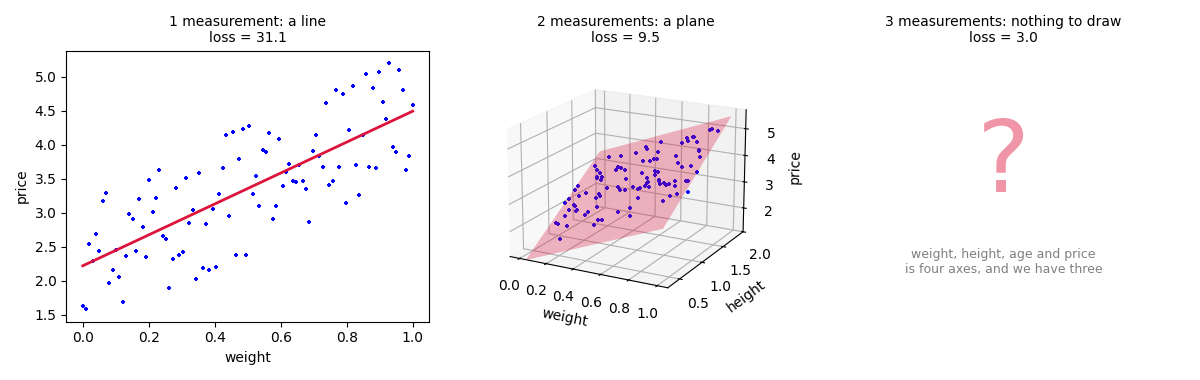

In [ ]:
fig_axes = plt.figure(figsize=(12, 3.8))

theta2, loss2 = best_parameters(x, height)
theta3, loss3 = best_parameters(x, height, age)

ax_a = fig_axes.add_subplot(1, 3, 1)
ax_a.scatter(x, y, c="b", s=7, marker="+")
ax_a.plot(x, BEST_1[1] * x + BEST_1[0], c="crimson", lw=2)
ax_a.set_xlabel("weight"); ax_a.set_ylabel("price")
ax_a.set_title(f"1 measurement: a line\nloss = {LOSS_1:.1f}", fontsize=10)

ax_b = fig_axes.add_subplot(1, 3, 2, projection="3d")
ax_b.scatter(x, height, y, c="b", s=7, marker="+", depthshade=False)
ax_b.plot_surface(GRID_W, GRID_H, theta2[0] + theta2[1] * GRID_W + theta2[2] * GRID_H,
                  color="crimson", alpha=0.3, linewidth=0, shade=False)
ax_b.set_xlabel("weight"); ax_b.set_ylabel("height"); ax_b.set_zlabel("price", labelpad=2)
ax_b.set_zlim(y.min() - 0.5, y.max() + 0.5)
ax_b.view_init(elev=18, azim=-62)
ax_b.set_title(f"2 measurements: a plane\nloss = {loss2:.1f}", fontsize=10)

ax_c = fig_axes.add_subplot(1, 3, 3)
ax_c.axis("off")
ax_c.text(0.5, 0.58, "?", ha="center", va="center", fontsize=72, color="crimson", alpha=0.45)
ax_c.text(0.5, 0.22, "weight, height, age and price\nis four axes, and we have three",
          ha="center", va="center", fontsize=9, color="gray")
ax_c.set_title(f"3 measurements: nothing to draw\nloss = {loss3:.1f}", fontsize=10)

fig_axes.tight_layout()
print(f"loss: {LOSS_1:.1f} -> {loss2:.1f} -> {loss3:.1f}   (every measurement helps)")
print(f"3 measurements, theta = {np.round(theta3, 3)}")

The loss keeps falling and the drawing is gone. Nothing went wrong: a fourth axis is not
missing from matplotlib, it is missing from the room.

So from here on **the formula is the only thing that still scales**, and that is the entire
reason the notation is about to change. Not rigour. Not elegance. We ran out of axes.

<details>
<summary>why is $\theta_0$ negative with three measurements ?</summary>

$\color{#FFB454}{\theta_0}$ is where the formula lands for a sculpture weighing 0 kg, 0 m tall and
0 years old. No such sculpture exists, and nothing in the data is anywhere near it, so the fit has
no reason to make that corner sensible. It is the price the formula *extrapolates* to, not a price
anyone pays.
</details>

# 4. N measurements: a list, and one operation on it

With $\color{#FFB454}{N}$ measurements we would have to write

$$\color{#56D4F5}{\hat{y}} = \color{#FFB454}{\theta_1} \color{#7EE787}{x_1}
+ \color{#FFB454}{\theta_2} \color{#7EE787}{x_2}
+ \color{#FFB454}{\theta_3} \color{#7EE787}{x_3}
+ \dots + \color{#FFB454}{\theta_N} \color{#7EE787}{x_N} + \color{#FFB454}{\theta_0}$$

which nobody can write down for $\color{#FFB454}{N} = 1000$. But look at what that sum actually
asks you to do. Two lists of the same length. Multiply them in pairs. Add up the results.

That operation has a name, the **dot product**, and that is all it is.

In [ ]:
s = 50                             # a sculpture from the middle of the catalogue
one_sculpture = np.array([x[s], height[s], age[s]])
parameters = theta3[1:]            # theta_1, theta_2, theta_3

print("measurements :", np.round(one_sculpture, 2))
print("parameters   :", np.round(parameters, 3))
print()
print("pair them up and multiply:")
for m, p in zip(one_sculpture, parameters):
    print(f"   {m:>7.2f}  x  {p:>6.3f}  =  {m * p:>7.3f}")
print(f"   add them up        =  {(one_sculpture * parameters).sum():>7.3f}")
print(f"   and that is np.dot =  {np.dot(one_sculpture, parameters):>7.3f}")

measurements : [ 0.51  1.81 90.  ]
parameters   : [2.066 1.69  0.008]

pair them up and multiply:
      0.51  x   2.066  =    1.044
      1.81  x   1.690  =    3.058
     90.00  x   0.008  =    0.750
   add them up        =    4.852
   and that is np.dot =    4.852


### The one trick

The dot product swallowed every term except one. $\color{#FFB454}{\theta_0}$ is still sitting
outside the sum, because it has no measurement to multiply.

So **give it one**. Put a measurement at the front of every sculpture that is always
$\color{#7EE787}{1}$:

$$\color{#56D4F5}{\hat{y}} =
\color{#FFB454}{\theta_0} \cdot \color{#7EE787}{1}
+ \color{#FFB454}{\theta_1} \color{#7EE787}{x_1}
+ \dots + \color{#FFB454}{\theta_N} \color{#7EE787}{x_N}
\qquad = \qquad
\color{#FFB454}{\theta} \cdot \color{#7EE787}{x}$$

$\color{#FFB454}{\theta_0} \times \color{#7EE787}{1}$ is $\color{#FFB454}{\theta_0}$, so nothing
about the model changed. What changed is that there is no longer a special case: every parameter
multiplies a measurement, and the whole prediction is **one dot product**.

That column of ones is not bookkeeping. Take it away and the model loses the ability to sit
anywhere but the origin.

interactive(children=(Checkbox(value=True, description='column of 1s'), Output()), _dom_classes=('widget-inter…

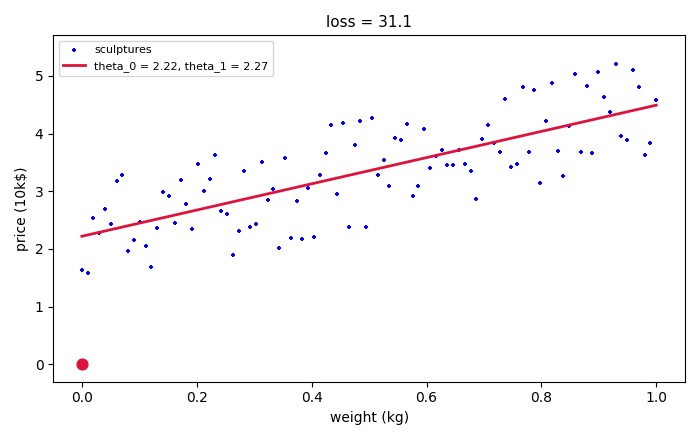

In [ ]:
fig_bias, ax_bias = plt.subplots(figsize=(7, 4.4))


@interact(ones_column=widgets.Checkbox(value=True, description="column of 1s"))
def without_the_ones(ones_column):
    ax_bias.clear()
    if ones_column:
        theta, loss = best_parameters(x)
        line = theta[0] + theta[1] * x
        label = f"theta_0 = {theta[0]:.2f}, theta_1 = {theta[1]:.2f}"
    else:
        # No ones column: theta_0 does not exist, so the line is nailed to (0, 0).
        slope = (x @ y) / (x @ x)
        line = slope * x
        loss = get_cost(y, line)
        label = f"theta_1 = {slope:.2f}, and no theta_0 at all"

    ax_bias.scatter(x, y, c="b", s=8, marker="+", label="sculptures")
    ax_bias.plot(x, line, c="crimson", lw=2, label=label)
    ax_bias.scatter([0], [0], c="crimson", s=60, marker="o", zorder=5)
    ax_bias.set_xlim(-0.05, 1.05); ax_bias.set_ylim(-0.3, y.max() + 0.5)
    ax_bias.set_xlabel("weight (kg)"); ax_bias.set_ylabel("price (10k$)")
    ax_bias.set_title(f"loss = {loss:.1f}", fontsize=11)
    ax_bias.legend(loc="upper left", fontsize=8)
    fig_bias.tight_layout()
    fig_bias.canvas.draw_idle()

# 5. Every sculpture at once

One sculpture is a list of measurements. The auction house has
100 of them, so stack the lists: one **row** per sculpture, one **column** per
measurement, and the column of $\color{#7EE787}{1}$s on the left.

That table is called $\color{#7EE787}{X}$, and the same dot product, applied to every row at once,
is written

$$\color{#56D4F5}{\hat{y}} = \color{#7EE787}{X} \cdot \color{#FFB454}{\theta}$$

One line of code predicts the price of every sculpture in the house.

In [ ]:
def bias_column(X):
    """Prepend the column of 1s, so theta_0 becomes an ordinary parameter."""
    return np.column_stack([np.ones(len(X)), X])


X = bias_column(np.column_stack([x, height, age]))

print("X is one row per sculpture, one column per measurement:", X.shape)
print("the first three rows, with the 1s in front:")
with np.printoptions(suppress=True, precision=2):
    print(X[:3])
print()
print("theta :", np.round(theta3, 3), "   shape", theta3.shape)
print("X @ theta gives every prediction at once:", (X @ theta3).shape)
print(f"\nfirst three predictions {np.round(X[:3] @ theta3, 2)}  against real {np.round(y[:3], 2)}")
print(f"loss {get_cost(y, X @ theta3):.1f}, the same number as the third panel above")

X is one row per sculpture, one column per measurement: (100, 4)
the first three rows, with the 1s in front:
[[  1.     0.     0.95  87.  ]
 [  1.     0.01   0.97  66.  ]
 [  1.     0.02   1.3  120.  ]]

theta : [-0.638  2.066  1.69   0.008]    shape (4,)
X @ theta gives every prediction at once: (100,)

first three predictions [1.69 1.57 2.6 ]  against real [1.64 1.58 2.54]
loss 3.0, the same number as the third panel above


# 6. And the derivatives ?

A formula we cannot differentiate is no use to us, so let us differentiate this one. Nothing new
is needed: it is the chain rule from notebook 3, applied to one parameter at a time.

Here is the loss, written with the dot product we just built. Sculpture $i$ is the row
$\color{#7EE787}{x_i}$ of $\color{#7EE787}{X}$, column of $\color{#7EE787}{1}$s included:

$$\color{#56D4F5}{\text{loss}} = \sum_i \big( \color{#7EE787}{x_i} \cdot
\color{#FFB454}{\theta} - \color{#7EE787}{y_i} \big)^2$$

Now pick **one** parameter, $\color{#FFB454}{\theta_j}$, and differentiate with respect to it.

- Outside is a square, so it brings down a $2$ and lowers the power: $2(\dots)$.
- Inside is a sum of $N+1$ terms, and $\color{#FFB454}{\theta_j}$ appears in exactly one of them,
  multiplied by $\color{#7EE787}{X_{ij}}$. Every other term is a constant as far as
  $\color{#FFB454}{\theta_j}$ is concerned, so the inner derivative is just
  $\color{#7EE787}{X_{ij}}$.

$$\frac{d\,\color{#56D4F5}{\text{loss}}}{d\color{#FFB454}{\theta_j}} =
\sum_i 2 \underbrace{\big( \color{#7EE787}{x_i} \cdot \color{#FFB454}{\theta} -
\color{#7EE787}{y_i} \big)}_{\text{error}_i} \cdot \; \color{#7EE787}{X_{ij}}$$

Which is exactly the shape of notebook 3's answer: twice the error, times whatever that parameter
was multiplying. One rule, for every parameter.

And look at what that sum does: two lists of length $n$ (the errors, and column $j$ of
$\color{#7EE787}{X}$), multiplied in pairs and added up. **It is a dot product again.**

So one derivative is one dot product, between the errors and a **column** of
$\color{#7EE787}{X}$. We want all $N+1$ of them.

Flipping a table so that its columns become its rows is called the **transpose**, written
$\color{#7EE787}{X}^{T}$. Once those columns are rows, taking all of the dot products at once is
the same matrix product we used for the predictions, and the whole gradient is one line:

$$\nabla_{\color{#FFB454}{\theta}}\,\color{#56D4F5}{\text{loss}}
= 2 \, \color{#7EE787}{X}^{T} (\color{#7EE787}{X} \color{#FFB454}{\theta} - \color{#7EE787}{y})$$

One entry per column of $\color{#7EE787}{X}$, which is one derivative per parameter.

Notebook 2b ended on a wish: every derivative out of a single pass over the data, instead of one
pass per parameter. This is it.

In [ ]:
# Differentiate one parameter at a time, exactly as above: twice the error, times the
# column that parameter multiplies.
start = np.zeros(4)                       # any theta works, zeros keep the numbers readable
errors = X @ start - y

names = ["the 1s", "weight", "height", "age"]
one_at_a_time = np.array([(2 * errors * X[:, j]).sum() for j in range(X.shape[1])])
for j, name in enumerate(names):
    print(f"d loss / d theta_{j}   (column {name:>6}) = {one_at_a_time[j]:>12.2f}")

all_at_once = 2 * X.T @ errors
print(f"\n2 * X.T @ errors, in one go       = {np.round(all_at_once, 2)}")
assert np.allclose(one_at_a_time, all_at_once), "the loop and the matrix form disagree"
print("\nfour derivatives, one matrix product, no loop")

# The age entry dwarfs the others only because age is measured in the hundreds while weight is
# under 1. Same formula, wildly different sizes: that is the whole reason feature scaling exists.

d loss / d theta_0   (column the 1s) =      -671.17
d loss / d theta_1   (column weight) =      -374.21
d loss / d theta_2   (column height) =      -848.29
d loss / d theta_3   (column    age) =    -74136.04

2 * X.T @ errors, in one go       = [  -671.17   -374.21   -848.29 -74136.04]

four derivatives, one matrix product, no loop


It should also reproduce, exactly, the two derivatives you worked out by hand in notebook 3:

$$\frac{d\,\text{loss}}{d\color{#FFB454}{a}} = \sum 2 \cdot \text{error} \cdot
\color{#7EE787}{x}
\qquad\qquad
\frac{d\,\text{loss}}{d\color{#FFB454}{b}} = \sum 2 \cdot \text{error}$$

Those two always look like one rule and one exception: one of them multiplies by
$\color{#7EE787}{x}$, and the other does not.

In [ ]:
# The same (a, b) the 3D hook in notebook 3 starts on, so the numbers are comparable.
a, b = 0.6, 0.6

X_1 = bias_column(x)                       # ones, then weight
theta_1 = np.array([b, a])                 # theta_0 = b, theta_1 = a
gradient = 2 * X_1.T @ (X_1 @ theta_1 - y)

# Notebook 3, by hand:
error = (a * x + b) - y
d_a = (2 * error * x).sum()
d_b = (2 * error).sum()

print(f"matrix form      {np.round(gradient, 6)}")
print(f"notebook 3       [{d_b:.6f} {d_a:.6f}]")
assert np.allclose(gradient, [d_b, d_a]), "the two forms disagree"
print("\nsame two numbers, in the same order as the columns of X")

matrix form      [-491.173206 -274.007819]
notebook 3       [-491.173206 -274.007819]

same two numbers, in the same order as the columns of X


Look at **which** entry came out as $\frac{d\,\text{loss}}{d\color{#FFB454}{b}}$: the
first one. The one belonging to the column of $\color{#7EE787}{1}$s.

$\color{#7EE787}{X}^{T}$ times the errors multiplies each column of $\color{#7EE787}{X}$ by the
errors and sums. For the weight column that gives $\sum 2 \cdot \text{error} \cdot
\color{#7EE787}{x}$. For the column of ones it gives $\sum 2 \cdot \text{error} \cdot
\color{#7EE787}{1}$, which is just $\sum 2 \cdot \text{error}$.

**That is why the bias derivative is the plain sum of the errors.** It was never a special rule to
memorise. It is the general rule, applied to a measurement that happens to be 1.

# This is exactly your Qwasar project

`My Linear Regression` asks for these, and you now have all of them:

| in the project | here |
|---|---|
| `h(x, theta)` | `X @ theta`, the prediction for every row |
| `bias_column(X)` | the column of $\color{#7EE787}{1}$s |
| `mean_squared_error(...)` | the loss |
| `LeastSquaresRegression` | $\color{#FFB454}{\theta} = (\color{#7EE787}{X}^{T}\color{#7EE787}{X})^{-1}\color{#7EE787}{X}^{T}\color{#7EE787}{y}$, which is the gradient above set to zero and solved |
| `GradientDescentOptimizer` | $\color{#FFB454}{\theta} \leftarrow \color{#FFB454}{\theta} - \text{lr} \cdot 2\color{#7EE787}{X}^{T}(\color{#7EE787}{X}\color{#FFB454}{\theta} - \color{#7EE787}{y})$ |

**One difference that will cost you an evening if nobody warns you.** This whole series uses a
**sum** of squared errors, and the project uses the **mean**:

$$\text{here}: \sum (\hat{y} - y)^2
\qquad\qquad
\text{project}: \frac{1}{n}\sum (\hat{y} - y)^2$$

Dividing the loss by $n$ divides its gradient by $n$ too. The direction is identical, the length is
not, so a learning rate tuned on one is $n$ times wrong on the other. With 100 sculptures, a
learning rate that behaves here will look completely dead there.